
Stopped


<Figure size 640x480 with 0 Axes>

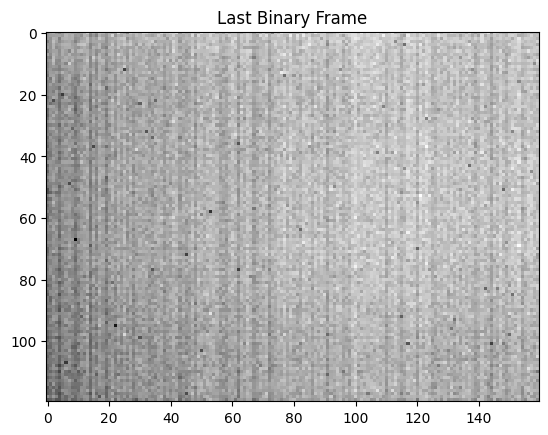

In [48]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime


class ImagePacketDecoder:
    """
    解析固定大小图像包
    包格式: FF FF + 大端 RAW16
    Binary 输出为对比度编码后的 u16 强度图
    """

    def __init__(self, width, height, calib_file=None):
        self.width = width
        self.height = height
        self.packet_size = 2 + width * height * 2

        self.calib = None
        if calib_file is not None:
            self._load_calibration(calib_file)

    def _load_calibration(self, calib_file):
        calib = np.load(calib_file)

        if calib.shape != (self.height, self.width):
            raise ValueError(
                f"Calibration shape mismatch: "
                f"expected {(self.height, self.width)}, got {calib.shape}"
            )

        # Binary 冰面，作为强度背景
        self.calib = calib.astype(np.int32)
        print(f"Loaded binary ice calibration: {calib_file}")

    @staticmethod
    def gray_to_binary(img):
        """Gray → Binary（对比度编码）"""
        bin16 = img.copy().astype(np.uint16)
        bin16 ^= bin16 >> 1
        bin16 ^= bin16 >> 2
        bin16 ^= bin16 >> 4
        bin16 ^= bin16 >> 8
        return bin16

    def feed_packet(self, packet):
        if len(packet) != self.packet_size:
            return None
        if packet[0] != 0xFF or packet[1] != 0xFF:
            return None

        data = packet[2:]
        buf8 = np.frombuffer(data, dtype=np.uint8)

        raw16 = (buf8[0::2].astype(np.uint16) << 8) | \
                buf8[1::2].astype(np.uint16)

        img_raw = raw16.reshape((self.height, self.width))

        # ===== RAW → Binary（对比度图）=====
        img_bin = self.gray_to_binary(img_raw).astype(np.int32)
        img_raw = img_bin

        # ===== Binary 冰面校准（强度差分）=====
        if self.calib is not None:
            img_bin = img_bin - self.calib
            img_bin = np.clip(img_bin, 0, 65535)

        return img_bin.astype(np.uint16), img_raw


def run_uart_capture(
    port,
    baud,
    width,
    height,
    calib_file=None,
):
    folder = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    os.makedirs(folder, exist_ok=True)

    raw_path = os.path.join(folder, "1.npy")
    print(f"Raw frames will be saved to: {raw_path}")

    decoder = ImagePacketDecoder(width, height, calib_file)

    buf = bytearray()
    frames_raw = []
    last_bin = None

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("Receiving frames... Press Ctrl-C to stop")

            while True:
                chunk = ser.read(2048)
                if not chunk:
                    continue

                buf.extend(chunk)

                while True:
                    idx = buf.find(b'\xFF\xFF')
                    if idx < 0:
                        if len(buf) > 1:
                            buf = buf[-1:]
                        break

                    if len(buf) - idx < decoder.packet_size:
                        buf = buf[idx:]
                        break

                    packet = buf[idx:idx + decoder.packet_size]
                    buf = buf[idx + decoder.packet_size:]

                    result = decoder.feed_packet(packet)
                    if result is None:
                        continue

                    img_bin, img_raw = result
                    frames_raw.append(img_raw)
                    last_bin = img_bin

                    # np.save(raw_path, np.array(frames_raw))
                    np.save(raw_path, img_raw)

                    clear_output(wait=True)
                    plt.imshow(img_bin, cmap="gray")
                    plt.title(f"Binary Contrast Image ({len(frames_raw)} frames)")
                    plt.show()

    except KeyboardInterrupt:
        print("\nStopped")

        if last_bin is not None:
            plt.figure()
            plt.imshow(last_bin, cmap="gray")
            plt.title("Last Binary Frame")
            plt.show()

import os
if __name__ == "__main__":
    print(os.getcwd())  # 看当前目录
    print(os.listdir('.'))  # 看有哪些文件夹
    run_uart_capture(
        port="COM31",
        baud=5_000_000,
        width=160,
        height=120,
        calib_file=None,  # ← 有校准文件就填路径，没有就 None
    )


In [39]:
import numpy as np

# 读取校准文件
calib = np.load("30.2摄氏度原始u16.npy").astype(np.uint16)
height, width = calib.shape

# 转一维
calib_flat = calib.flatten()

with open("calib.h", "w") as f:
    f.write("#ifndef CALIB_H\n#define CALIB_H\n\n")
    f.write(f"#define CALIB_WIDTH {width}\n")
    f.write(f"#define CALIB_HEIGHT {height}\n")
    f.write(f"#define CALIB_SIZE {width*height}\n\n")
    f.write(f"const uint16_t calib[CALIB_SIZE] = {{\n")

    # 每行 16 个元素，方便阅读
    for i in range(0, len(calib_flat), 16):
        row = calib_flat[i:i+16]
        row_str = ", ".join(str(x) for x in row)
        f.write(f"    {row_str},\n")

    f.write("};\n\n#endif // CALIB_H\n")
